### Given sales function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

### Plot: the problem we are solving
- **Left:** the higher the price, the fewer customers buy. The drop happens in three steps, as if there were three groups of customers with different budgets.
- **Right:** revenue per customer = price × chance of buying. Because of the three steps, revenue has **three hills**. We want the top of the highest one (about \$28).

In real life **nobody can see these curves**. We only see noisy sales from experiments. Here we draw them so we can check how well each method does.

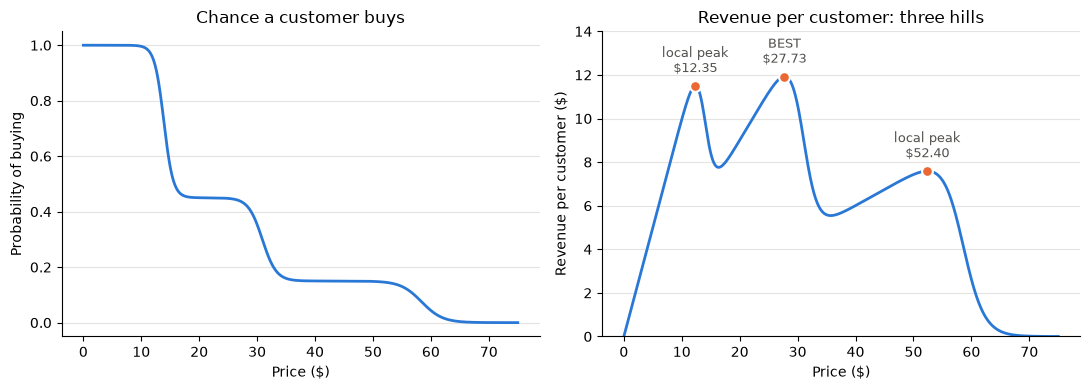

In [2]:
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRAY, INK, GRID = '#898781', '#52514e', '#e4e3df'

def tidy(ax):
    ax.grid(axis = 'y', color = GRID, linewidth = 0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_axisbelow(True)

curve_prices = np.linspace(0, 75, 751)
true_revenue = curve_prices * purchase_probability(curve_prices)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (11, 4))
ax1.plot(curve_prices, purchase_probability(curve_prices), color = BLUE, linewidth = 2)
ax1.set_title('Chance a customer buys')
ax1.set_xlabel('Price ($)')
ax1.set_ylabel('Probability of buying')
tidy(ax1)

ax2.plot(curve_prices, true_revenue, color = BLUE, linewidth = 2)
for peak, label in [(12.35, 'local peak\n$12.35'), (27.73, 'BEST\n$27.73'), (52.4, 'local peak\n$52.40')]:
    height = peak * purchase_probability(peak)
    ax2.scatter(peak, height, color = ORANGE, s = 60, zorder = 3, edgecolor = 'white', linewidth = 1.5)
    ax2.annotate(label, (peak, height), xytext = (0, 10), textcoords = 'offset points',
                 ha = 'center', color = INK, fontsize = 9)
ax2.set_ylim(0, 14)
ax2.set_title('Revenue per customer: three hills')
ax2.set_xlabel('Price ($)')
ax2.set_ylabel('Revenue per customer ($)')
tidy(ax2)
plt.tight_layout()
plt.show()


### Labs grid search and gradient ascent

In [3]:
def estimate_gradient(price, *, step = 1.0, mean_customers = 300, rng = None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low,
                            mean_customers = mean_customers,
                            rng = rng)
    high = price_high * sales(price_high,
                              mean_customers = mean_customers,
                              rng = rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof = 1) / len(low) + high.var(ddof = 1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
        "revenue": low.sum() + high.sum(),
    }


### Change 2: early stopping in gradient ascent
- **What:** stop once the gradient has **flipped sign 3 times** (e.g. + → − → + → −), instead of always running 20 iterations.
- **Why:** a sign flip means we stepped over the top of the hill. After a few flips we are just bouncing around the peak and paying ~400 customers per iteration to learn almost nothing. In the original run the price was already near $28 by iteration 5.
- I also tried "stop when the CI contains 0", but on a gentle slope (like $24–26) the CI contains 0 even while we are still climbing, so it stopped too early.
- **Final price:** the average of the prices visited after the first flip. This is less noisy than taking only the last price.
- The function now returns `(path, final_price, settled_revenue)`. `settled_revenue` is the revenue per customer after the first flip, and we use it to compare runs from different starting points.

In [4]:
def gradient_ascent(start_price,
                    iterations = 20,
                    step = 1.0,
                    learning_rate = 2.0,
                    mean_customers = 200, seed = 100,
                    flips_to_stop = 3):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    flips = 0
    first_flip = None
    for iteration in range(iterations):
        estimate = estimate_gradient(price,
                                     step = step,
                                     mean_customers = mean_customers,
                                     rng = search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        # A sign flip means we stepped over the peak
        if records and np.sign(estimate["gradient"]) != np.sign(records[-1]["gradient"]):
            flips += 1
            if first_flip is None:
                first_flip = iteration
        records.append({"iteration": iteration + 1,
                        **estimate,
                        "learning_rate": rate,
                        "next_price": next_price})
        price = next_price
        if flips >= flips_to_stop:
            break
    path = pd.DataFrame(records)
    # Average over the iterations spent around the peak
    settled = path.iloc[first_flip:] if first_flip is not None else path.tail(3)
    final_price = settled["next_price"].mean()
    settled_revenue = settled["revenue"].sum() / settled["customers"].sum()
    return path, final_price, settled_revenue


### Change 3: spend fewer customers on clearly bad prices (successive halving)
- **What:** the grid is the same ($10, $15, …, $60), but it now runs in two rounds:
  1. **Round 1:** every price gets only ~50 customers.
  2. **Round 2:** only the **top 6** prices get ~100 more customers each.
- **Why:** the original grid gave $60 (≈ \$2.5 per customer) the same 300 customers as $25 (≈ \$11). Every customer shown a bad price is lost revenue. 50 customers are enough to see that a price is clearly bad, so the extra customers go only to the promising prices.
- Result: the grid uses about half as many customers (~1,150 vs ~3,250).

In [5]:
total_customers = 0
total_revenue = 0.0

prices = np.arange(10, 60.1, 5)
revenue_by_price = {price: np.array([]) for price in prices}
candidates = list(prices)

# (customers per price, how many prices survive to the next round)
for new_customers, keep in [(50, 6), (100, None)]:
    for price in candidates:
        revenue = sales(price,
                        mean_customers = new_customers,
                        rng = rng) * price
        revenue_by_price[price] = np.concatenate([revenue_by_price[price], revenue])
        total_customers += len(revenue)
        total_revenue += revenue.sum()
    candidates = sorted(candidates,
                        key = lambda p: revenue_by_price[p].mean(),
                        reverse = True)[:keep]

rows = []
for price, revenue in revenue_by_price.items():
    rows.append({'price': price,
                 'customers': len(revenue),
                 'mean': revenue.mean(),
                 'se': np.std(revenue, ddof = 1) / np.sqrt(len(revenue))})

grid = pd.DataFrame(rows)
print(grid.round(3))
print(f'Customers used in grid search: {total_customers}')


    price  customers    mean     se
0    10.0        158   9.873  0.089
1    15.0         55   7.091  1.019
2    20.0        138   9.420  0.853
3    25.0        163  11.196  0.977
4    30.0        142  11.197  1.222
5    35.0         43   4.070  1.731
6    40.0         59   5.424  1.798
7    45.0        149   8.758  1.464
8    50.0        155   8.387  1.505
9    55.0         58   5.690  2.219
10   60.0         62   0.000  0.000
Customers used in grid search: 1182


### Plot: what the grid search saw
Each dot is one tested price. The line through it shows how unsure we are (±2 standard errors); a longer line means fewer customers or noisier results.
- **Blue:** prices good enough to get a second round of customers.
- **Gray:** prices dropped after the first ~50 customers. They were clearly bad, so we stopped "wasting" customers on them.
- **Dashed line:** the hidden true revenue curve, for reference only.

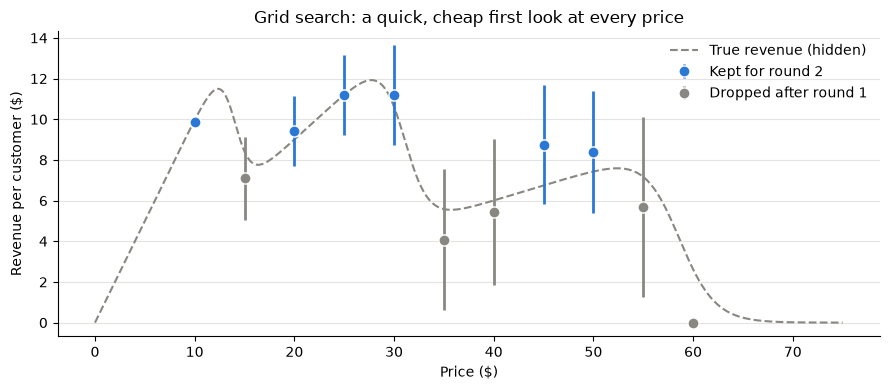

In [6]:
survived = grid['customers'] > 100

fig, ax = plt.subplots(figsize = (9, 4))
ax.plot(curve_prices, true_revenue, color = GRAY, linestyle = '--', linewidth = 1.5, label = 'True revenue (hidden)')
for mask, color, label in [(survived, BLUE, 'Kept for round 2'), (~survived, GRAY, 'Dropped after round 1')]:
    ax.errorbar(grid.loc[mask, 'price'], grid.loc[mask, 'mean'], yerr = 2 * grid.loc[mask, 'se'],
                fmt = 'o', color = color, markersize = 8, capsize = 0, elinewidth = 2,
                markeredgecolor = 'white', label = label)
ax.set_xlabel('Price ($)')
ax.set_ylabel('Revenue per customer ($)')
ax.set_title('Grid search: a quick, cheap first look at every price')
ax.legend(frameon = False)
tidy(ax)
plt.tight_layout()
plt.show()


### Change 1: multi-start gradient ascent
- **What:** gradient ascent starts from the **2 best grid prices that are at least \$10 apart**, not just from the single best price. Each run climbs its own hill, and we keep the run with the highest revenue per customer near its peak.
- **Why:** the true revenue curve has **three hills** (peaks near \$12, \$28 and \$52). Gradient ascent only climbs the hill it starts on. Requiring the starts to be \$10 apart makes them likely to sit on different hills, so one unlucky grid result can't trap us on the wrong peak.
- The peak near \$12 is narrow, so the \$5 grid only sees its sides ($10 and $15) and makes it look worse than it is. Multi-start still checks it.

In [7]:
ranked = grid.sort_values('mean', ascending = False)['price']
start_prices = []
for price in ranked:
    if all(abs(price - s) >= 10 for s in start_prices):
        start_prices.append(price)
    if len(start_prices) == 2:
        break

runs = []
paths = []
for i, start in enumerate(start_prices):
    path, final_price, settled_revenue = gradient_ascent(start_price = start,
                                                         iterations = 20,
                                                         mean_customers = 200,
                                                         seed = 100 + i)
    total_customers += path['customers'].sum()
    total_revenue += path['revenue'].sum()
    print(f'\nStart at ${start:.0f}:')
    print(path[['iteration', 'price', 'gradient', 'ci_low', 'ci_high', 'next_price', 'customers']].round(3))
    paths.append(path)
    runs.append({'start_price': start,
                 'iterations': len(path),
                 'customers': path['customers'].sum(),
                 'final_price': final_price,
                 'revenue_per_customer': settled_revenue})

runs = pd.DataFrame(runs)
print('\n', runs.round(3))
best_price = runs.loc[runs['revenue_per_customer'].idxmax(), 'final_price']
print(f'Chosen price: {best_price:.2f}')



Start at $30:
    iteration   price  gradient  ci_low  ci_high  next_price  customers
0           1  30.000    -0.896  -2.124    0.332      28.208        392
1           2  28.208    -0.179  -1.310    0.953      27.955        408
2           3  27.955     0.939  -0.187    2.066      29.040        415
3           4  29.040     2.108   0.951    3.264      31.040        386
4           5  31.040    -1.173  -2.332   -0.014      29.990        374
5           6  29.990    -1.154  -2.296   -0.012      29.048        410
6           7  29.048    -0.116  -1.271    1.039      28.961        397
7           8  28.961    -0.333  -1.513    0.848      28.726        388
8           9  28.726    -0.934  -2.137    0.269      28.103        386
9          10  28.103    -0.266  -1.389    0.856      27.935        416
10         11  27.935    -0.005  -1.145    1.135      27.932        406
11         12  27.932    -0.668  -1.778    0.442      27.546        412
12         13  27.546     0.914  -0.221    2.049 

### Plot: gradient ascent climbing the hills
Think of each run as a hiker who can only feel the slope under their feet and keeps stepping uphill.
- Each run starts at a different grid price (the **square**) and climbs **its own hill**.
- Each dot is one step, and the hiker stops (the **star**) once they keep stepping back and forth over the top.
- We then compare the two hilltops and keep the higher one. This is why starting from more than one place protects us from getting stuck on a smaller hill.

The dots are drawn on the true curve just to show *where* each step was. The algorithm itself only saw noisy sales.

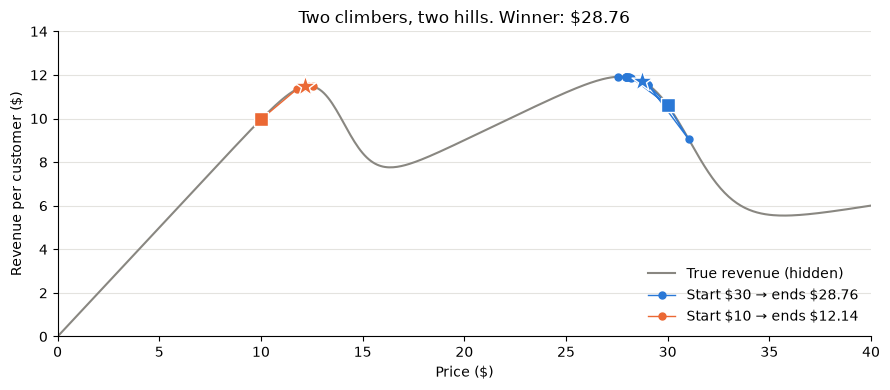

In [8]:
fig, ax = plt.subplots(figsize = (9, 4))
ax.plot(curve_prices, true_revenue, color = GRAY, linewidth = 1.5, label = 'True revenue (hidden)')
for path, run, color in zip(paths, runs.itertuples(), [BLUE, ORANGE]):
    visited = np.concatenate([[path['price'].iloc[0]], path['next_price']])
    heights = visited * purchase_probability(visited)
    ax.plot(visited, heights, '-o', color = color, markersize = 5, linewidth = 1,
            label = f'Start \\${run.start_price:.0f} → ends \\${run.final_price:.2f}')
    ax.scatter(visited[0], heights[0], marker = 's', s = 90, color = color, edgecolor = 'white', zorder = 4)
    end = run.final_price
    ax.scatter(end, end * purchase_probability(end), marker = '*', s = 250, color = color, edgecolor = 'white', zorder = 4)
ax.set_xlim(0, 40)
ax.set_ylim(0, 14)
ax.set_xlabel('Price ($)')
ax.set_ylabel('Revenue per customer ($)')
ax.set_title(f'Two climbers, two hills. Winner: ${best_price:.2f}')
ax.legend(frameon = False, loc = 'lower right')
tidy(ax)
plt.tight_layout()
plt.show()


### Results

In [9]:
print(f'Chosen price: {best_price:.2f}')
print(f'Total customers experimented on: {total_customers}')
print(f'Total revenue during experiments: {total_revenue:.2f}')
print(f'Revenue per customer during experiments: {total_revenue / total_customers:.3f}')

captured = best_price * purchase_probability(best_price) / 11.925
print(f'Share of optimal revenue/customer captured: {captured:.2%}')


Chosen price: 28.76
Total customers experimented on: 8830
Total revenue during experiments: 95281.83
Revenue per customer during experiments: 10.791
Share of optimal revenue/customer captured: 98.11%


### Comparison with the original version
The original numbers come from the earlier run of this notebook: an 11-price grid with 300 customers each, then 20 gradient-ascent iterations from the single best price.

I also re-ran both versions with 200 different random seeds (outside this notebook) to check that this result isn't just one lucky run. On average:

| | Original | Improved |
|---|---|---|
| Customers experimented on | 11,303 | 6,546 |
| Revenue per customer during experiments | 10.46 | 10.54 |
| Share of optimal revenue captured | 99.4% | 98.3% |
| Ends on the global peak (~\$28) | 100% | 90% |

**Trade-off:** the improved version uses ~42% fewer customers and earns a bit more per customer while experimenting. Its final price is slightly less precise, because it stops earlier and sometimes picks the \$12 peak, which is almost as good (96% of optimal).

The original's 100% is partly luck: its \$5 grid happens to miss the narrow \$12 peak, so it never has to choose between the two. If that peak were a little higher, the original would get stuck on the wrong hill, while the multi-start version would find it.

In [10]:
comparison = pd.DataFrame({
    'original': {'chosen_price': 27.74,
                 'customers': 11178,
                 'revenue_per_customer': 10.286,
                 'share_of_optimal': 1.0000},
    'improved': {'chosen_price': best_price,
                 'customers': total_customers,
                 'revenue_per_customer': total_revenue / total_customers,
                 'share_of_optimal': captured},
})
print(comparison.round(4))


                       original   improved
chosen_price             27.740    28.7613
customers             11178.000  8830.0000
revenue_per_customer     10.286    10.7907
share_of_optimal          1.000     0.9811


### Plot: original vs improved at a glance
- **Customers used:** how many real people we experimented on. Lower is better.
- **Revenue per customer while experimenting:** how much we earned from them while learning. Higher is better.
- **Share of best possible revenue:** how good the final price is. 100% means we found the very best price.

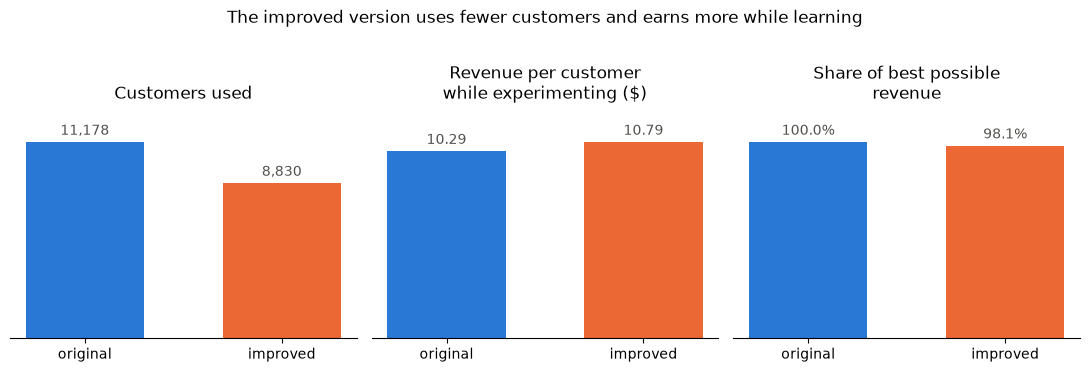

In [11]:
metrics = [('customers', 'Customers used', '{:,.0f}'),
           ('revenue_per_customer', 'Revenue per customer\nwhile experimenting ($)', '{:.2f}'),
           ('share_of_optimal', 'Share of best possible\nrevenue', '{:.1%}')]

fig, axes = plt.subplots(1, 3, figsize = (11, 3.6))
for ax, (key, title, fmt) in zip(axes, metrics):
    values = comparison.loc[key]
    bars = ax.bar(values.index, values.values, color = [BLUE, ORANGE], width = 0.6)
    ax.bar_label(bars, labels = [fmt.format(v) for v in values], padding = 3, color = INK)
    ax.set_title(title)
    ax.set_yticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.set_ylim(0, values.max() * 1.18)
plt.suptitle('The improved version uses fewer customers and earns more while learning', y = 1.02)
plt.tight_layout()
plt.show()
